# Objective

To determine whether size or location is the determining factor in Housing Prices

# 1. Problem Statement

I want to findout beyond reasonable doubt if size or location has the strongest explanatory factor in predicting house prices in mexico by Using median and std as my comparison tool. The result of this investigation will help potential home buyers make better decision when buying a house or an apartment. This is not a regression problem.

# 2. Hypothesis

Main Hypothesis: Location has stronger explanatory 
                 power than size in predicting 
                 Mexican house prices
│

├── Branch 1 — SIZE
│   └── Do large areas tend to have higher prices?
│       → corr(area_m2, price_usd)²
│

├── Branch 2 — LOCATION
│   └── Does median price differ significantly across states?
│       → groupby state → median price → R²
│

├── Branch 3 — CONFOUNDING VARIABLE
│   └── How does property type in states affect price?
│       → groupby state + property_type → median price
│

└── Branch 4 — VERDICT
    └── Does R² location > R² size?
        → Direct comparison → answers main hypothesis

# 3. Loading Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Loading Datasets

## df1

In [2]:
df1=pd.read_csv("mexico-real-estate-1.csv")
df1.columns=df1.columns.str.strip().str.lower()
df1_df=pd.DataFrame(df1)
display(df1.head())


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,"$67,965.56"
1,house,Nuevo León,25.688436,-100.198807,186.0,"$63,223.78"
2,apartment,Guerrero,16.767704,-99.764383,82.0,"$84,298.37"
3,apartment,Guerrero,16.829782,-99.911012,150.0,"$94,308.80"
4,house,Veracruz de Ignacio de la Llave,NaN,NaN,175.0,"$94,835.67"


In [3]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  700 non-null    object 
 1   state          700 non-null    object 
 2   lat            583 non-null    float64
 3   lon            583 non-null    float64
 4   area_m2        700 non-null    float64
 5   price_usd      700 non-null    object 
dtypes: float64(3), object(3)
memory usage: 32.9+ KB


In [21]:
df1.isnull().sum()

property_type      0
state              0
lat              117
lon              117
area_m2            0
price_usd          0
dtype: int64

## Data Cleaning for df1

Following a brief inspection of the provided dataset, specifically the first CSV file, `df1`, the following observations were made:

* The dataset contains **700 rows and 6 columns**.
* The `lat` and `lon` columns each contain **177 missing values**. Since these columns represent geographical coordinates, imputing the missing values could introduce inaccurate locations. Therefore, the rows with missing `lat` or `lon` values will be dropped.
* The `price_usd` column is currently stored as a **string** rather than a numerical data type. The dollar sign (`$`) and commas will be removed, after which the values will be converted to the **float** data type for further analysis.

These preprocessing steps will ensure that the dataset is appropriately formatted and ready for subsequent analysis.


In [4]:
df1=df1.dropna(subset=["lat","lon"])

In [5]:
df1["price_usd"]=df1["price_usd"].str.replace(",","",regex=False).str.replace("$","",regex=False).astype(float)

In [6]:
df1.head()

,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
5,house,Yucatán,21.052583,-89.538639,205.0,105191.37


In [7]:
df1.describe()

,lat,lon,area_m2,price_usd
count,583.000000,583.000000,583.000000,583.000000
mean,20.677211,-98.394698,168.655232,114485.628182
std,2.563123,4.797798,78.647018,65887.374860
min,16.717077,-117.033916,60.000000,33358.450000
25%,19.198379,-100.344878,102.000000,64418.715000
50%,19.559799,-99.180214,155.000000,97469.990000
75%,21.096664,-97.911407,215.500000,147522.150000
max,32.665619,-86.767539,385.000000,326733.660000


In [8]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 583 entries, 0 to 699
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  583 non-null    object 
 1   state          583 non-null    object 
 2   lat            583 non-null    float64
 3   lon            583 non-null    float64
 4   area_m2        583 non-null    float64
 5   price_usd      583 non-null    float64
dtypes: float64(4), object(2)
memory usage: 31.9+ KB


## df2

In [9]:
df2=pd.read_csv("mexico-real-estate-2.csv")
df2.columns=df2.columns.str.strip().str.lower()
df2_df=pd.DataFrame(df2)
display(df2.head())

,property_type,state,lat,lon,area_m2,price_mxn
0,apartment,Nuevo León,25.721081,-100.345581,72.0,1300000.0
1,apartment,Puebla,NaN,NaN,190.0,2500000.0
2,house,Morelos,23.634501,-102.552788,360.0,5300000.0
3,house,Morelos,NaN,NaN,76.0,820000.0
4,house,Puebla,NaN,NaN,200.0,1100000.0


In [10]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  700 non-null    object 
 1   state          700 non-null    object 
 2   lat            571 non-null    float64
 3   lon            571 non-null    float64
 4   area_m2        700 non-null    float64
 5   price_mxn      700 non-null    float64
dtypes: float64(4), object(2)
memory usage: 32.9+ KB


In [11]:
df2.isnull().sum()

property_type      0
state              0
lat              129
lon              129
area_m2            0
price_mxn          0
dtype: int64

## Data Cleaning for df2

Following a brief inspection of the provided dataset, specifically the second CSV file, `df2`, the following observations were made:

* The dataset contains **700 rows and 6 columns**.
* The `lat` and `lon` columns each contain **129 missing values**. Since these columns represent geographical coordinates, imputing the missing values could introduce inaccurate locations. Therefore, the rows with missing `lat` or `lon` values will be dropped.
* The `price_mxn` column is currently stored in mexican currency not usd, to ensure consistency `price_mxn` will be divided by 19 to convert it to price_usd.

**Note:** 19 doesnt mean its a constant conversion number.

These preprocessing steps will ensure that the dataset is appropriately formatted and ready for subsequent analysis.

In [12]:
df2=df2.dropna(subset=["lat","lon"])

In [13]:
df2 = df2.assign(price_usd=lambda x: x["price_mxn"] / 19)

In [14]:
df2=df2.drop("price_mxn",axis=1)

In [15]:
df2.head()

,property_type,state,lat,lon,area_m2,price_usd
0,apartment,Nuevo León,25.721081,-100.345581,72.0,68421.052632
2,house,Morelos,23.634501,-102.552788,360.0,278947.368421
6,apartment,Estado de México,19.272040,-99.572013,85.0,65789.473684
7,house,San Luis Potosí,22.138882,-100.996510,158.0,111578.947368
8,apartment,Distrito Federal,19.394558,-99.129707,65.0,39904.736842


In [16]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 571 entries, 0 to 699
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  571 non-null    object 
 1   state          571 non-null    object 
 2   lat            571 non-null    float64
 3   lon            571 non-null    float64
 4   area_m2        571 non-null    float64
 5   price_usd      571 non-null    float64
dtypes: float64(4), object(2)
memory usage: 31.2+ KB


In [17]:
df2.describe()

,lat,lon,area_m2,price_usd
count,571.000000,571.000000,571.000000,571.000000
mean,20.983555,-99.012350,172.129597,115195.212554
std,2.959004,5.227166,79.951591,64544.318365
min,16.228815,-117.038495,60.000000,33157.894737
25%,19.287224,-100.442642,110.000000,66052.631579
50%,20.302476,-99.201675,157.000000,97894.736842
75%,21.156042,-98.244797,228.000000,150000.000000
max,32.647057,-86.817017,383.000000,321052.631579


## df3

In [18]:
df3=pd.read_csv("mexico-real-estate-3.csv")
df3.columns=df3.columns.str.strip().str.lower()
df3_df=pd.DataFrame(df3)
display(df3.head())

,property_type,place_with_parent_names,lat-lon,area_m2,price_usd
0,apartment,|México|Distrito Federal|Gustavo A. Madero|Acu...,"19.52589,-99.151703",71.0,48550.59
1,house,|México|Estado de México|Toluca|Metepec|,"19.2640539,-99.5727534",233.0,168636.73
2,house,|México|Estado de México|Toluca|Toluca de Lerd...,"19.268629,-99.671722",300.0,86932.69
3,house,|México|Morelos|Temixco|Burgos Bugambilias|,NaN,275.0,263432.41
4,apartment,|México|Veracruz de Ignacio de la Llave|Veracruz|,"19.511938,-96.871956",84.0,68508.67


In [19]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   property_type            700 non-null    object 
 1   place_with_parent_names  700 non-null    object 
 2   lat-lon                  582 non-null    object 
 3   area_m2                  700 non-null    float64
 4   price_usd                700 non-null    float64
dtypes: float64(2), object(3)
memory usage: 27.5+ KB


In [20]:
df3.isnull().sum()

property_type                0
place_with_parent_names      0
lat-lon                    118
area_m2                      0
price_usd                    0
dtype: int64

## Data Cleaning for df3

Following a brief inspection of the provided dataset, specifically the third CSV file, `df3`, the following observations were made:

* The dataset contains **700 rows and 6 columns**.
* The `lat` and `lon` values were concatenated into a single `lat-lon` column. These were separated into individual `lat` and `lon` columns, null values were removed, and the values were converted to floats.
* The `place_with_parent_names` column contained location information in the format `country|state|...`. A new `State` column was created by extracting only the state information.
* The original `place_with_parent_names` and `lat-lon` columns were subsequently dropped, leaving the dataset with the required **6 columns**.

These preprocessing steps ensure that the dataset is appropriately formatted and ready for concatenation.


In [21]:
df3[["lat","lon"]]=df3["lat-lon"].str.split(",",expand=True).astype(float)
df3["state"]=df3["place_with_parent_names"].str.split("|").str[2]

df3 = df3.drop(["place_with_parent_names", "lat-lon"], axis=1)

df3.head()

,property_type,area_m2,price_usd,lat,lon,state
0,apartment,71.0,48550.59,19.525890,-99.151703,Distrito Federal
1,house,233.0,168636.73,19.264054,-99.572753,Estado de México
2,house,300.0,86932.69,19.268629,-99.671722,Estado de México
3,house,275.0,263432.41,NaN,NaN,Morelos
4,apartment,84.0,68508.67,19.511938,-96.871956,Veracruz de Ignacio de la Llave


In [22]:
df3=df3.dropna(subset=["lat","lon"])

In [23]:
df3.head()

,property_type,area_m2,price_usd,lat,lon,state
0,apartment,71.0,48550.59,19.525890,-99.151703,Distrito Federal
1,house,233.0,168636.73,19.264054,-99.572753,Estado de México
2,house,300.0,86932.69,19.268629,-99.671722,Estado de México
4,apartment,84.0,68508.67,19.511938,-96.871956,Veracruz de Ignacio de la Llave
5,house,175.0,102763.00,20.689157,-103.366728,Jalisco


In [24]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 582 entries, 0 to 699
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  582 non-null    object 
 1   area_m2        582 non-null    float64
 2   price_usd      582 non-null    float64
 3   lat            582 non-null    float64
 4   lon            582 non-null    float64
 5   state          582 non-null    object 
dtypes: float64(4), object(2)
memory usage: 31.8+ KB


In [25]:
df3.describe()

,area_m2,price_usd,lat,lon
count,582.000000,582.000000,582.000000,582.000000
mean,170.037801,116313.970911,20.639739,-98.993412
std,83.208768,65919.612586,2.689661,4.591151
min,60.000000,33192.480000,15.752900,-117.054763
25%,100.000000,62613.202500,19.276006,-100.393310
50%,159.000000,100655.040000,19.539792,-99.216015
75%,218.000000,155315.762500,21.031325,-98.933026
max,380.000000,326733.660000,32.601212,-86.812320


## Concantenating df1, df2 and df3

In [26]:
df=pd.concat([df1,df2,df3], ignore_index=True)

In [27]:
df.to_csv("Cleaned-mexico-real-estate-data.csv",index=False)

In [28]:
df.head()

,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37


# 5. Exploratory Data Analysis

## Data Understanding - Univariate Analysis

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1736 entries, 0 to 1735
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  1736 non-null   object 
 1   state          1736 non-null   object 
 2   lat            1736 non-null   float64
 3   lon            1736 non-null   float64
 4   area_m2        1736 non-null   float64
 5   price_usd      1736 non-null   float64
dtypes: float64(4), object(2)
memory usage: 81.5+ KB


In [30]:
df.describe(include="object")

,property_type,state
count,1736,1736
unique,2,30
top,house,Distrito Federal
freq,1329,303


In [31]:
df.describe()

,lat,lon,area_m2,price_usd
count,1736.000000,1736.000000,1736.000000,1736.000000
mean,20.765410,-98.798575,170.261521,115331.980800
std,2.743425,4.882553,80.594539,65426.173793
min,15.752900,-117.054763,60.000000,33157.894737
25%,19.275200,-100.392553,101.750000,65789.473684
50%,19.620518,-99.204001,156.000000,99262.132105
75%,21.073428,-98.245911,220.000000,150846.665000
max,32.665619,-86.767539,385.000000,326733.660000


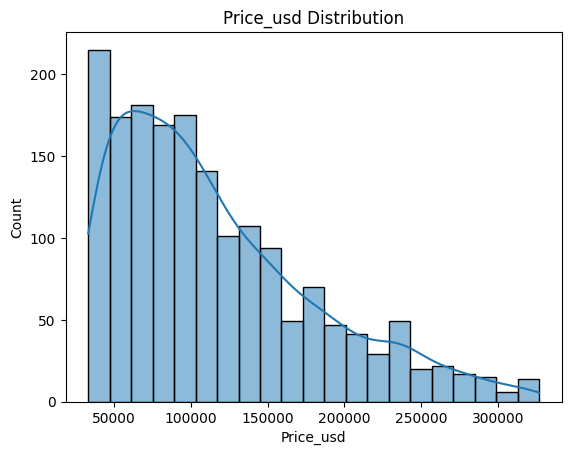

In [32]:
sns.histplot(data=df,x="price_usd",kde=True)
plt.title("Price_usd Distribution")
plt.ylabel("Count")
plt.xlabel("Price_usd")
plt.show()


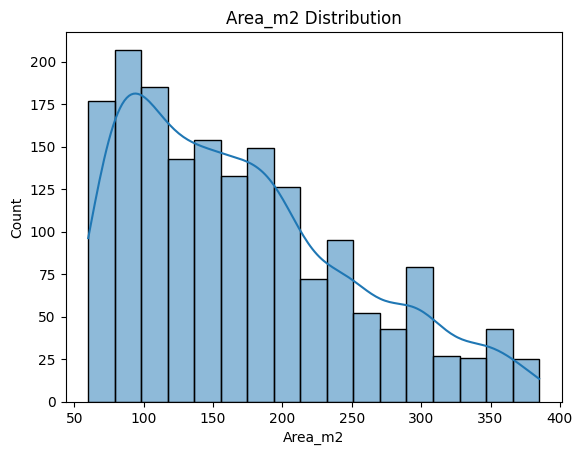

In [33]:
sns.histplot(data=df,x="area_m2",kde=True)
plt.title("Area_m2 Distribution")
plt.ylabel("Count")
plt.xlabel("Area_m2")
plt.show()

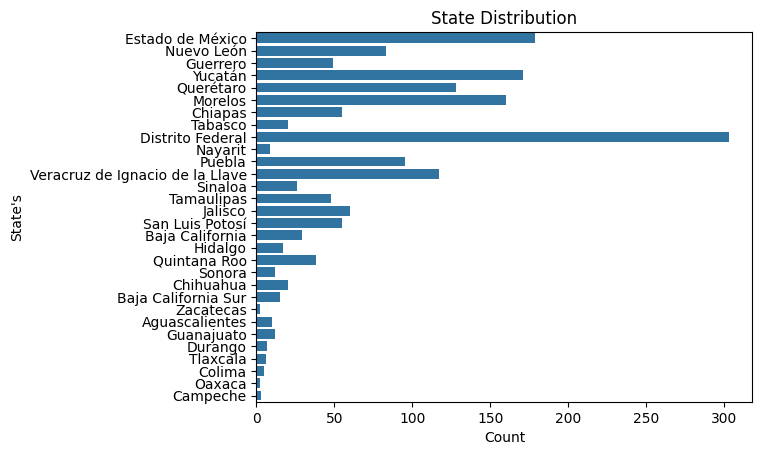

In [44]:
sns.countplot(data=df,y="state")
plt.title("State Distribution")
plt.ylabel("State's")
plt.xlabel("Count")
plt.show()

Since the price data is highly right-skewed, we can cap extreme values at the 5th and 90th percentiles to reduce the influence of unusually low and high prices on our analysis. This helps limit the impact of outliers while retaining most of the data.


In [46]:
df["price_usd"]=df["price_usd"].clip(lower=df["price_usd"].quantile(0.05),upper=df["price_usd"].quantile(0.90))

In [47]:
df.describe()

,lat,lon,area_m2,price_usd
count,1736.000000,1736.000000,1736.000000,1736.000000
mean,20.765410,-98.798575,170.261521,110939.198718
std,2.743425,4.882553,80.594539,55355.873922
min,15.752900,-117.054763,60.000000,39232.060000
25%,19.275200,-100.392553,101.750000,65789.473684
50%,19.620518,-99.204001,156.000000,99262.132105
75%,21.073428,-98.245911,220.000000,150846.665000
max,32.665619,-86.767539,385.000000,210795.910000


# 6. Analysis

## Branch 1 — SIZE - Do large areas tend to have higher prices?

In [ ]:
b1=df["area_m2"].corr(df["price_usd"])
print(b1)

0.6042702376409155


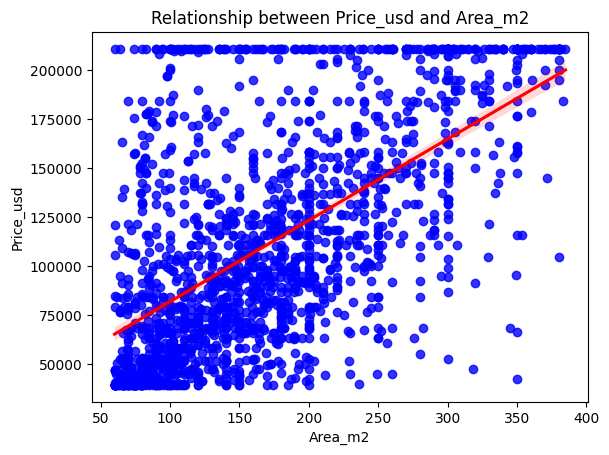

In [55]:
sns.regplot(data=df,x="area_m2",y="price_usd",ci=95,  color="blue",line_kws={"color": "red"})
plt.title("Relationship between Price_usd and Area_m2")
plt.ylabel("Price_usd")
plt.xlabel("Area_m2")
plt.show()

## Branch 2 — LOCATION - Does median price differ significantly across states?

In [58]:
b2=df.groupby("state").apply(lambda x: x["area_m2"].corr(x["price_usd"])).sort_values(ascending=False)
print(b2)

state
Zacatecas                          1.000000
Colima                             0.988235
Durango                            0.916118
Sonora                             0.915033
Aguascalientes                     0.872370
Baja California Sur                0.870570
Querétaro                          0.852973
Morelos                            0.849432
San Luis Potosí                    0.837423
Campeche                           0.824161
Hidalgo                            0.818788
Nayarit                            0.774295
Puebla                             0.762797
Chiapas                            0.762063
Yucatán                            0.755407
Chihuahua                          0.748726
Tamaulipas                         0.744214
Tlaxcala                           0.726152
Baja California                    0.660782
Guerrero                           0.654374
Estado de México                   0.643422
Guanajuato                         0.637360
Sinaloa                   

C:\Users\Suleiman Umar Farouk\AppData\Local\Temp\ipykernel_19488\2562453830.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  b2=df.groupby("state").apply(lambda x: x["area_m2"].corr(x["price_usd"])).sort_values(ascending=False)


In [64]:
b2 = df.groupby("state").apply(lambda x: x["area_m2"].corr(x["price_usd"])).sort_values(ascending=False).aggregate(["median", "std","mean"])
print(b2)


median    0.752066
std       0.355073
mean      0.678030
dtype: float64


C:\Users\Suleiman Umar Farouk\AppData\Local\Temp\ipykernel_19488\2360564789.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  b2 = df.groupby("state").apply(lambda x: x["area_m2"].corr(x["price_usd"])).sort_values(ascending=False).aggregate(["median", "std","mean"])


## Branch 3 — CONFOUNDING VARIABLE - How does property type in states affect price?

In [71]:
b3=df.groupby(["property_type","state"]).apply(lambda x: x["area_m2"].corr(x["price_usd"])).reset_index(name="correlation")
b3_df=pd.DataFrame(b3)
print(b3)

   property_type                            state  correlation
0      apartment                  Baja California     0.964303
1      apartment              Baja California Sur          NaN
2      apartment                          Chiapas     0.378860
3      apartment                 Distrito Federal     0.505385
4      apartment                          Durango          NaN
5      apartment                 Estado de México     0.702334
6      apartment                         Guerrero     0.707353
7      apartment                          Jalisco     0.830480
8      apartment                          Morelos     0.693295
9      apartment                       Nuevo León    -0.065052
10     apartment                           Oaxaca    -1.000000
11     apartment                           Puebla     0.410025
12     apartment                        Querétaro     0.808082
13     apartment                     Quintana Roo     0.799003
14     apartment                  San Luis Potosí     0

c:\Users\Suleiman Umar Farouk\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3057: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
c:\Users\Suleiman Umar Farouk\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:2914: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
c:\Users\Suleiman Umar Farouk\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:2914: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
C:\Users\Suleiman Umar Farouk\AppData\Local\Temp\ipykernel_19488\1843146338.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the gro

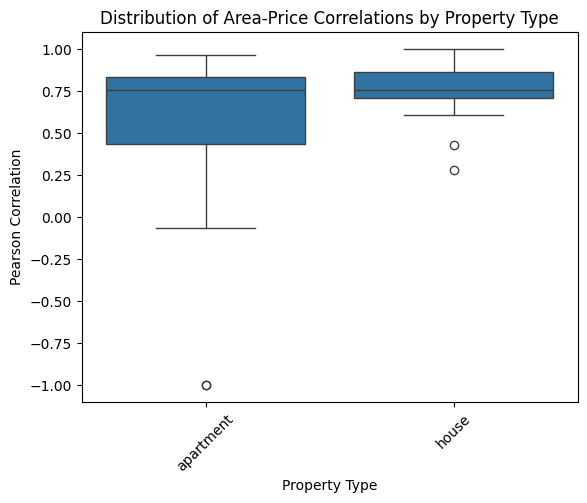

In [72]:
sns.boxplot(
    data=b3_df,
    x="property_type",
    y="correlation"
)

plt.title("Distribution of Area-Price Correlations by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Pearson Correlation")
plt.xticks(rotation=45)
plt.show()

In [73]:
b3 = (df.groupby(["property_type", "state"]).apply(lambda x: x["area_m2"].corr(x["price_usd"])).groupby(level="property_type").agg(["mean", "median", "std"]))
print(b3)

                   mean    median       std
property_type                              
apartment      0.500618  0.753178  0.599526
house          0.764591  0.753355  0.154420


c:\Users\Suleiman Umar Farouk\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3057: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
c:\Users\Suleiman Umar Farouk\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:2914: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
c:\Users\Suleiman Umar Farouk\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:2914: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
C:\Users\Suleiman Umar Farouk\AppData\Local\Temp\ipykernel_19488\3402202775.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the gro

# 7. Analysis Summary

### Branch 1: Overall Relationship Between Property Size and Price

The Pearson correlation coefficient between property size and price is **0.60**, indicating a moderate positive relationship. The coefficient of determination (\(R^2\)) is approximately **36%**, suggesting that a simple linear relationship with property size accounts for 36% of the observed variation in price, while the remaining 64% is unexplained by this model.

To investigate this relationship further, I developed a regression plot. One key observation was the uneven spread of data points across property sizes. Properties between 50 and 150 m² are densely concentrated, with considerable vertical dispersion in prices. Beyond 500 m², observations become sparser, and lower-priced properties become less prevalent, resulting in a different distribution pattern.

These observations suggest that the relationship between property size and price may vary across the range of property sizes. They also support my initial hypothesis that **location may have a stronger relationship with price than property size**, although further analysis is required to establish this.

### Branch 2: Variation in the Size–Price Relationship Across States

Across states, the median correlation coefficient is **0.75**, corresponding to a squared median correlation of approximately **56%**. The mean correlation is **0.68**, with its square giving approximately **46%**.

I prioritised the median over the mean because some states have correlation coefficients as high as 1.00, yet contain fewer than four observations. Such small samples can produce extreme correlation estimates that are not representative of the underlying market. Similarly, negative correlations in some states suggest that the size–price relationship is not consistent across geographical locations.

The most notable finding is the **standard deviation of 0.36**, indicating substantial variation in correlation coefficients across states. This suggests that the relationship between property size and price is highly dependent on the state being analysed.

Further investigation is necessary to understand this variation. Potential next steps include examining sample sizes, identifying outliers, and engineering additional features that capture location-specific characteristics.

### Branch 3: Differences Between Houses and Apartments

The median correlation coefficient between property size and price is **0.75 for both houses and apartments**. However, their mean correlations differ: **0.76 for houses and 0.50 for apartments**.

The difference may be influenced by the distribution and number of observations in each category, particularly because houses account for 1,329 observations. The standard deviation is **0.15 for houses and 0.60 for apartments**, suggesting that the size–price relationship is considerably more variable for apartments.

These findings indicate that property type may influence the relationship between size and price. This branch also provides additional context for Branch 2, as it suggests that the relationship may vary across different property categories, potentially contributing to the variation observed across states.

However, property type should not yet be classified as a confirmed confounding variable. Further analysis is needed to establish whether it explains part of the observed relationship between property size, location, and price.

### Branch 4: Comparing Property Size and Location

The overall correlation between property size and price is **0.60**, while the median state-level correlation is **0.75**. Based on these figures, location appears to have the stronger relationship with property price, with a difference of **0.15** between the two correlation coefficients.

However, this preliminary advantage should be interpreted cautiously. The standard deviation of state-level correlations is **0.36**, indicating considerable variation across states. Furthermore, the comparison is between an overall correlation and a median of state-level correlations, which are not directly equivalent measures.

Consequently, although location currently appears to be the stronger candidate, the evidence is not yet sufficient to conclude that it is the dominant factor influencing property prices.

Further analysis should include feature engineering, consideration of sample sizes, and a multivariable regression model incorporating property size, location, and property type. These steps would help determine whether location provides additional explanatory power beyond property size and whether the observed differences remain after accounting for other relevant variables.

### Overall Conclusion

The preliminary analysis suggests that property size is positively associated with price, but the strength of this relationship varies across states and property types. Location appears to offer a stronger relationship with price than property size, although the observed differences and substantial variation across states warrant further investigation.

The next stage will focus on feature engineering to determine the relative contribution of property size, location, and property type to explaining property prices.


# 8. Findings Synthesis

This investigation set out to determine whether size or location has stronger explanatory power over house prices in Mexico. Prior to analysis, it was hypothesised that location has higher explanatory power than size because houses in cities cost more than in rural areas. The analysis revealed that location explains 56% of price variance compared to size which explains 36%, suggesting that location has more explanatory power. However, the standard deviation of 0.36 across state correlations raises questions about whether location truly offers more explanatory power. Therefore, while the evidence tentatively supports location, further analysis through feature engineering is needed before a definitive conclusion can be drawn.


# 9. Recommendation

Based on the findings of this investigation, it is not yet advisable for home buyers to use these results to guide purchasing decisions. The standard deviation of 0.36 across state correlations indicates that location's explanatory power is highly inconsistent across Mexico, making a definitive conclusion premature. Analysts wishing to continue this work are advised to pursue three specific next steps: first, engineer a price_per_m² feature to investigate the source of the high variability across states; second, drop states with fewer than a minimum sample threshold as their near-perfect correlations are statistical artifacts rather than real market signals; third, analyse houses and apartments separately given that property type has been identified as a confounding variable with significantly different correlation behaviours across both groups.